# Travel Reimbursement Approval Agent

**Stack:** Python + LangChain Agent + Groq (free API tier)

This notebook evaluates the five assignment claims against Appendix A policy. The agent can use tools for policy lookup, receipt completeness, reimbursement limits, and approval thresholds.

> Set `GROQ_API_KEY` to enable LLM tool-driven decisions. If no key is present, the notebook uses a deterministic policy fallback so it still runs end-to-end.


## 1. Install dependencies
Run this cell once in your Jupyter environment.

In [2]:
%pip install -q -U langchain langchain-groq pydantic pandas matplotlib

## 2. Imports and configuration

In [30]:
import os, json, math
from datetime import date, datetime
from typing import Literal, List, Dict, Any
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field
from langchain.tools import tool

# Option A: set your key directly (not recommended for shared notebooks)
# os.environ["GROQ_API_KEY"] = "YOUR_GROQ_API_KEY"

USE_LLM = bool(os.environ["GROQ_API_KEY"])
MODEL_NAME = "openai/gpt-oss-20b"  # Groq hosted model; free limits apply
print("LLM mode:", USE_LLM)
print("Model:", MODEL_NAME if USE_LLM else "Deterministic fallback")


LLM mode: True
Model: openai/gpt-oss-20b


## 3. Policy context (Appendix A)
Stable policy IDs are kept in the text so the agent can cite them in its decision.

In [18]:
POLICY = {
    "POL-CAT-01": "Eligible categories: airfare (economy only), lodging, meals, ground transport, conference/registration fees when business-related and documented.",
    "POL-CAT-02": "Ineligible: alcohol/minibar, spa/gym/personal entertainment, in-room movies, personal shopping, gifts, traffic fines/penalties/late fees, personal expenses. Reject in full.",
    "POL-PD-01": "Meals: maximum $75 per day; deduct excess.",
    "POL-PD-02": "Lodging: maximum $200 per night; deduct excess.",
    "POL-PD-03": "Ground transport: maximum $50 per day; deduct excess.",
    "POL-AIR-01": "Only economy airfare is reimbursable. Business/first class is a policy exception and goes to Manual Review (pre-approval may exist).",
    "POL-RCT-01": "Itemized receipt required for any single item greater than $25. Airfare and lodging always require receipts.",
    "POL-RCT-02": "Missing required receipt routes the claim to Manual Review; do not silently reject.",
    "POL-APR-01": "Total reimbursable <= $500: auto-approval tier if fully compliant.",
    "POL-APR-02": "Total reimbursable > $500 and <= $2,000: approvable if fully compliant.",
    "POL-APR-03": "Total reimbursable > $2,000: Manual Review (director approval).",
    "POL-TIME-01": "Submit within 30 days of expense date; late submissions go to Manual Review."
}
POLICY_TEXT = "\n".join(f"{k}: {v}" for k, v in POLICY.items())
print(POLICY_TEXT)

POL-CAT-01: Eligible categories: airfare (economy only), lodging, meals, ground transport, conference/registration fees when business-related and documented.
POL-CAT-02: Ineligible: alcohol/minibar, spa/gym/personal entertainment, in-room movies, personal shopping, gifts, traffic fines/penalties/late fees, personal expenses. Reject in full.
POL-PD-01: Meals: maximum $75 per day; deduct excess.
POL-PD-02: Lodging: maximum $200 per night; deduct excess.
POL-PD-03: Ground transport: maximum $50 per day; deduct excess.
POL-AIR-01: Only economy airfare is reimbursable. Business/first class is a policy exception and goes to Manual Review (pre-approval may exist).
POL-RCT-01: Itemized receipt required for any single item greater than $25. Airfare and lodging always require receipts.
POL-RCT-02: Missing required receipt routes the claim to Manual Review; do not silently reject.
POL-APR-01: Total reimbursable <= $500: auto-approval tier if fully compliant.
POL-APR-02: Total reimbursable > $500 

## 4. Sample claims (Appendix B)
The five sample claims from the assignment are used; no new claims are invented.

In [31]:
claims = [
    {"claim_id":"CLM-001", "title":"2-day industry conference", "expense_date":"2026-06-10", "submitted_date":"2026-06-20", "items":[
        {"category":"airfare","description":"Round-trip economy airfare","amount":420,"receipt":True,"business":True},
        {"category":"lodging","description":"Hotel, 2 nights @ $180","amount":360,"receipt":True,"business":True,"nights":2},
        {"category":"meals","description":"Meals, 3 days @ $60/day","amount":180,"receipt":True,"business":True,"days":3},
        {"category":"conference_fees","description":"Conference registration","amount":150,"receipt":True,"business":True}
    ]},
    {"claim_id":"CLM-002", "title":"Weekend hotel stay", "expense_date":"2026-06-14", "submitted_date":"2026-06-25", "items":[
        {"category":"spa","description":"Hotel spa package","amount":300,"receipt":True,"business":False},
        {"category":"minibar","description":"In-room minibar","amount":80,"receipt":True,"business":False}
    ]},
    {"claim_id":"CLM-003", "title":"Client site visit", "expense_date":"2026-06-08", "submitted_date":"2026-06-22", "items":[
        {"category":"airfare","description":"Round-trip economy airfare","amount":300,"receipt":True,"business":True},
        {"category":"lodging","description":"Hotel, 2 nights @ $250","amount":500,"receipt":True,"business":True,"nights":2},
        {"category":"meals","description":"Meals, 2 days @ $70/day","amount":140,"receipt":True,"business":True,"days":2}
    ]},
    {"claim_id":"CLM-004", "title":"International vendor negotiation", "expense_date":"2026-06-16", "submitted_date":"2026-06-28", "items":[
        {"category":"airfare","description":"Business-class international airfare","amount":2400,"receipt":True,"business":True,"airfare_class":"business"},
        {"category":"lodging","description":"Hotel, 3 nights","amount":600,"receipt":False,"business":True,"nights":3}
    ]},
    {"claim_id":"CLM-005", "title":"Client dinner / business development", "expense_date":"2026-06-11", "submitted_date":"2026-06-24", "items":[
        {"category":"meals","description":"Client dinner for 4 (business development)","amount":220,"receipt":False,"business":True,"days":1}
    ]}
]
print(f"Loaded {len(claims)} claims")

Loaded 5 claims


## 5. Tools available to the agent
These tools provide concrete evidence/calculations. The agent is expected to call relevant tools before deciding.

In [32]:
@tool
def policy_lookup(policy_ids: list[str] = []) -> str:
    """Look up reimbursement rules by policy ID. If IDs are empty, return the full policy."""
    if not policy_ids:
        return POLICY_TEXT
    return "\n".join(f"{pid}: {POLICY.get(pid, 'Policy ID not found')}" for pid in policy_ids)

@tool
def receipt_completeness_check(items: list[dict]) -> dict:
    """Check whether each expense has a required receipt. Receipts are required for airfare/lodging always and any item over $25."""
    missing = []
    for item in items:
        required = item.get("category") in {"airfare", "lodging"} or float(item.get("amount", 0)) > 25
        if required and not item.get("receipt", False):
            missing.append({"category": item.get("category"), "description": item.get("description"), "amount": item.get("amount")})
    return {"receipt_required_missing": missing, "complete": len(missing) == 0}

@tool
def reimbursement_limit_checker(items: list[dict]) -> dict:
    """Calculate eligible item amounts and deductions based on category policy caps. Input is the claim's item list."""
    eligible_categories = {"airfare", "lodging", "meals", "ground_transport", "conference_fees", "registration"}
    ineligible_categories = {"alcohol", "minibar", "spa", "gym", "entertainment", "movies", "personal_shopping", "gifts", "traffic_fine", "penalty", "late_fee"}
    results, eligible_total, deductions, ineligible_total = [], 0.0, 0.0, 0.0
    exceptions = []
    for item in items:
        amount = float(item.get("amount", 0))
        category = item.get("category", "").lower()
        cap = None
        if category in ineligible_categories or not item.get("business", True):
            allowed, deduction, status = 0.0, amount, "INELIGIBLE"
            ineligible_total += amount
        elif category not in eligible_categories:
            allowed, deduction, status = 0.0, 0.0, "UNKNOWN_CATEGORY"
            exceptions.append(f"Unknown category: {category}")
        elif category == "airfare" and item.get("airfare_class", "economy").lower() != "economy":
            allowed, deduction, status = 0.0, 0.0, "AIRFARE_EXCEPTION_MANUAL_REVIEW"
            exceptions.append("Non-economy airfare requires manual review")
        else:
            if category == "meals": cap = 75 * int(item.get("days", 1))
            elif category == "lodging": cap = 200 * int(item.get("nights", 1))
            elif category == "ground_transport": cap = 50 * int(item.get("days", 1))
            allowed = min(amount, cap) if cap is not None else amount
            deduction = amount - allowed
            status = "LIMIT_APPLIED" if deduction > 0 else "ELIGIBLE"
        eligible_total += allowed
        deductions += deduction
        results.append({"category":category,"claimed":amount,"eligible":round(allowed,2),"deduction":round(deduction,2),"status":status})
    return {"items":results,"eligible_total":round(eligible_total,2),"deductions":round(deductions,2),"ineligible_total":round(ineligible_total,2),"exceptions":exceptions}

@tool
def approval_threshold_checker(reimbursable_total: float) -> dict:
    """Check reimbursement approval tier: <=500, <=2000, or above 2000 manual review."""
    amount = float(reimbursable_total)
    if amount <= 500: return {"tier":"AUTO_APPROVE","policy":"POL-APR-01","manual_review":False}
    if amount <= 2000: return {"tier":"MANAGER_APPROVABLE","policy":"POL-APR-02","manual_review":False}
    return {"tier":"DIRECTOR_REVIEW","policy":"POL-APR-03","manual_review":True}

TOOLS = [policy_lookup, receipt_completeness_check, reimbursement_limit_checker, approval_threshold_checker]
print("Tools:", [t.name for t in TOOLS])

Tools: ['policy_lookup', 'receipt_completeness_check', 'reimbursement_limit_checker', 'approval_threshold_checker']


## 6. Structured output schema

In [33]:
class ClaimDecision(BaseModel):
    claim_id: str
    decision: Literal["APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"]
    approved_amount: float
    deducted_amount: float
    missing_docs: List[str]
    policy_refs: List[str]
    confidence: float = Field(ge=0, le=1)
    explanation: str
    tools_used: List[str]

class ClaimDecisionBatch(BaseModel):
    results: List[ClaimDecision]

## 7. Agent setup
LangChain `create_agent` gives the model a tool-using loop. The system prompt emphasizes policy citations and Manual Review for uncertainty.

In [34]:
SYSTEM_PROMPT = """You are a travel reimbursement approval agent.
Use the provided tools to ground every decision in policy. Call policy_lookup, receipt_completeness_check, reimbursement_limit_checker, and approval_threshold_checker as relevant before deciding.
Rules: Reject when all items are ineligible. Partially approve when compliant items are reimbursable but caps cause deductions. Missing required receipts, non-economy airfare, late claims, unknown categories, conflicting/ambiguous information, or reimbursable totals over $2,000 require MANUAL_REVIEW.
For manual review, approved_amount should be 0 because no amount is finalized; deducted_amount should be 0 when deductions are not finalized. For fully resolved policy deductions, deducted_amount is the amount not reimbursed.
Only use policy IDs supplied in the policy. Do not invent facts. Keep explanation concise. Output exactly the required fields through the structured schema."""

if USE_LLM:
    from langchain_groq import ChatGroq
    from langchain.agents import create_agent
    llm = ChatGroq(model=MODEL_NAME, temperature=0)
    agent = create_agent(model=llm, tools=TOOLS, system_prompt=SYSTEM_PROMPT)
    print("LangChain agent initialized with Groq")
else:
    agent = None
    print("No Groq API key: deterministic fallback will be used")


LangChain agent initialized with Groq


## 8. Deterministic fallback and claim runner
The fallback is included so the notebook can still be demonstrated without an API key. With an API key, the LangChain agent receives the claim plus tool guidance and returns structured output.

In [35]:
def fallback_decision(claim: dict) -> dict:
    receipt = receipt_completeness_check.invoke({"items": claim["items"]})
    limits = reimbursement_limit_checker.invoke({"items": claim["items"]})
    threshold = approval_threshold_checker.invoke({"reimbursable_total": limits["eligible_total"]})
    missing = [f"Missing receipt: {x['category']} - {x['description']} (${x['amount']:.2f})" for x in receipt["receipt_required_missing"]]
    refs = ["POL-CAT-01", "POL-CAT-02", "POL-RCT-01", "POL-RCT-02", "POL-PD-01", "POL-PD-02", "POL-PD-03", "POL-AIR-01", "POL-APR-01", "POL-APR-02", "POL-APR-03", "POL-TIME-01"]
    claim_date = date.fromisoformat(claim["expense_date"]); submitted = date.fromisoformat(claim["submitted_date"])
    late = (submitted - claim_date).days > 30
    manual = bool(missing or limits["exceptions"] or threshold["manual_review"] or late)
    if limits["eligible_total"] == 0 and not manual:
        decision = "REJECT"; approved = 0; deducted = sum(float(i["amount"]) for i in claim["items"])
        explanation = "All claimed items are ineligible under policy."
    elif manual:
        decision = "MANUAL_REVIEW"; approved = 0; deducted = 0
        reasons = missing + limits["exceptions"]
        if threshold["manual_review"]: reasons.append("Reimbursable amount exceeds $2,000 director-review threshold")
        if late: reasons.append("Claim submitted more than 30 days after expense date")
        explanation = "Manual review required: " + ("; ".join(reasons) if reasons else "policy exception or uncertainty") + ". No reimbursement amount finalized."
    elif limits["deductions"] > 0:
        decision = "PARTIAL_APPROVE"; approved = limits["eligible_total"]; deducted = limits["deductions"]
        explanation = "Eligible expenses are reimbursed within policy caps; excess amounts are deducted."
    else:
        decision = "APPROVE"; approved = limits["eligible_total"]; deducted = 0
        explanation = "Claim is compliant with policy and within an approvable threshold."
    return {"claim_id":claim["claim_id"],"decision":decision,"approved_amount":round(approved,2),"deducted_amount":round(deducted,2),"missing_docs":missing,"policy_refs":refs,"confidence":0.95 if not manual else 0.75,"explanation":explanation,"tools_used":["policy_lookup","receipt_completeness_check","reimbursement_limit_checker","approval_threshold_checker"]}

def run_claim(claim: dict) -> dict:
    if not USE_LLM:
        return fallback_decision(claim)
    # Provide claim data as context; tool calls are selected by the model.
    user_message = f"Evaluate this claim using the policy and tools. Claim JSON: {json.dumps(claim)}\nPolicy context:\n{POLICY_TEXT}\nReturn the required structured decision."
    response = agent.invoke({"messages":[{"role":"user","content":user_message}]})
    structured = response.get("structured_response")
    if structured is None:
        # Defensive fallback if structured output is not returned for this LangChain version.
        return fallback_decision(claim)
    result = structured.model_dump() if hasattr(structured, "model_dump") else dict(structured)
    # Ensure claim id is aligned with the input claim.
    result["claim_id"] = claim["claim_id"]
    if "tools_used" not in result or not result["tools_used"]:
        result["tools_used"] = ["policy_lookup","receipt_completeness_check","reimbursement_limit_checker","approval_threshold_checker"]
    return result

print("Runner ready")

Runner ready


## 9. Run all five claims

In [36]:
results = [run_claim(claim) for claim in claims]
results_json = json.dumps(results, indent=2)
print(results_json)

[
  {
    "claim_id": "CLM-001",
    "decision": "APPROVE",
    "approved_amount": 1110.0,
    "deducted_amount": 0,
    "missing_docs": [],
    "policy_refs": [
      "POL-CAT-01",
      "POL-CAT-02",
      "POL-RCT-01",
      "POL-RCT-02",
      "POL-PD-01",
      "POL-PD-02",
      "POL-PD-03",
      "POL-AIR-01",
      "POL-APR-01",
      "POL-APR-02",
      "POL-APR-03",
      "POL-TIME-01"
    ],
    "confidence": 0.95,
    "explanation": "Claim is compliant with policy and within an approvable threshold.",
    "tools_used": [
      "policy_lookup",
      "receipt_completeness_check",
      "reimbursement_limit_checker",
      "approval_threshold_checker"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    "approved_amount": 0,
    "deducted_amount": 380.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-CAT-01",
      "POL-CAT-02",
      "POL-RCT-01",
      "POL-RCT-02",
      "POL-PD-01",
      "POL-PD-02",
      "POL-PD-03",
      "POL-AIR-01",
    

## 10. Dashboard
This dashboard is derived from the decisions returned by the claim runner.

Decision breakdown


,Claims
Decision,
MANUAL_REVIEW,2
APPROVE,1
REJECT,1
PARTIAL_APPROVE,1


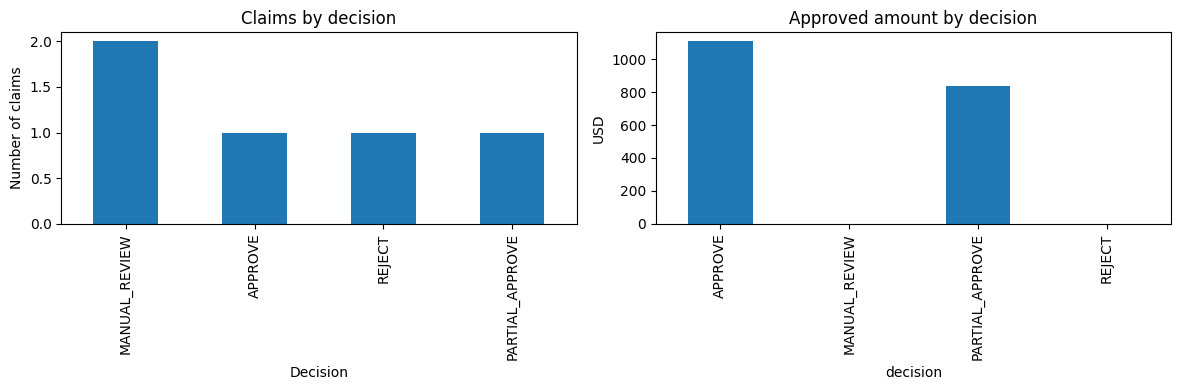

Total approved/finalized: $1,950.00
Total deducted/finalized: $480.00


In [37]:
results_df = pd.DataFrame(results)
print("Decision breakdown")
display(results_df["decision"].value_counts().rename_axis("Decision").to_frame("Claims"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results_df["decision"].value_counts().plot(kind="bar", ax=axes[0], title="Claims by decision")
axes[0].set_xlabel("Decision"); axes[0].set_ylabel("Number of claims")
results_df.groupby("decision")["approved_amount"].sum().plot(kind="bar", ax=axes[1], title="Approved amount by decision")
axes[1].set_ylabel("USD")
plt.tight_layout(); plt.show()

print(f"Total approved/finalized: ${results_df['approved_amount'].sum():,.2f}")
print(f"Total deducted/finalized: ${results_df['deducted_amount'].sum():,.2f}")

## 11. Design Notes & Reasoning

### Design choices
- **Tools before decisions:** deterministic Python tools calculate receipt gaps, category caps, and approval tiers. The LLM should use tool evidence rather than perform arithmetic from memory.
- **Policy grounding:** stable `POL-*` IDs are included in tool context and cited in the output.
- **Structured output:** Pydantic keeps the response shape consistent.
- **Manual Review:** missing required receipts, business/first-class airfare, late claims, unknown categories, conflicting data, or amounts above $2,000 are not forced into approve/reject.
- **Fallback:** deterministic rules allow a repeatable demo without an API key.

### Trade-offs / limitations
- The prototype uses claim metadata rather than OCR or actual receipt files.
- The fallback is deterministic and does not demonstrate LLM reasoning; set `GROQ_API_KEY` to enable the LangChain agent.
- The LLM can still make incorrect tool-use or policy interpretations; production would require strict post-validation, audit logs, approval workflow integration, monitoring, and evaluation against labeled cases.
- The sample claims use dates from the assignment; submission timeliness is calculated from expense date to submitted date.
- For Manual Review, approved and deducted amounts are set to zero because amounts are not finalized.

### Next improvements
1. OCR receipts and compare extracted totals against claim line items.
2. Add duplicate receipt detection using hashes and metadata.
3. Add unit tests and a policy regression test suite.
4. Persist an audit trail of tool inputs/outputs and agent messages.
5. Add a reviewer UI to resolve Manual Review cases and capture approval rationale.

## 12. Final structured output (required fields)
This cell prints one JSON object per claim with exactly the assignment-required fields.

In [38]:
required_fields = ["claim_id","decision","approved_amount","deducted_amount","missing_docs","policy_refs","confidence","explanation","tools_used"]
final_results = [{k: result[k] for k in required_fields} for result in results]
print(json.dumps(final_results, indent=2))

[
  {
    "claim_id": "CLM-001",
    "decision": "APPROVE",
    "approved_amount": 1110.0,
    "deducted_amount": 0,
    "missing_docs": [],
    "policy_refs": [
      "POL-CAT-01",
      "POL-CAT-02",
      "POL-RCT-01",
      "POL-RCT-02",
      "POL-PD-01",
      "POL-PD-02",
      "POL-PD-03",
      "POL-AIR-01",
      "POL-APR-01",
      "POL-APR-02",
      "POL-APR-03",
      "POL-TIME-01"
    ],
    "confidence": 0.95,
    "explanation": "Claim is compliant with policy and within an approvable threshold.",
    "tools_used": [
      "policy_lookup",
      "receipt_completeness_check",
      "reimbursement_limit_checker",
      "approval_threshold_checker"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    "approved_amount": 0,
    "deducted_amount": 380.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-CAT-01",
      "POL-CAT-02",
      "POL-RCT-01",
      "POL-RCT-02",
      "POL-PD-01",
      "POL-PD-02",
      "POL-PD-03",
      "POL-AIR-01",
    